# GAN & WGAN Training over SHVN

**Pablo Martínez Olmos, Vanessa Gómez Verdejo,  Alejandro Lancho Serrano, Emilio Parrado Hernández**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='https://upload.wikimedia.org/wikipedia/commons/8/88/Acronimo_nombre3l.jpg' width=300 />



This notebook demonstrates training both a standard GAN and a Wasserstein GAN (WGAN/WGAN-GP) on the SVHN (Street View House Numbers) dataset using PyTorch. We cover data loading, model definitions, training loops, and visualizations.

In [109]:
# Imports and Setup
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torchvision.utils as vutils
import os

# Set specific GPU (e.g., GPU 0)
gpu_id = 0
device = torch.device(f"cuda:{gpu_id}" if torch.cuda.is_available() else "cpu")
torch.cuda.set_device(device)

# Output directory
os.makedirs("svhn_gan_output", exist_ok=True)

# Parameters
image_size = 32
batch_size = 128
nz = 100  # Latent vector size
ngf = 64  # Generator feature maps
ndf = 64  # Discriminator feature maps
nc = 3    # RGB channels


In [90]:
print(f"Using device: {device}")

Using device: cuda:0


## 2. Dataset Loading and Preprocessing
We use the `SVHN` dataset from `torchvision.datasets`, resizing images to 32x32 and normalizing them. The data loader shuffles batches for training.

In [91]:
# Load SVHN Dataset
transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

svhn_dataset = datasets.SVHN(
    root="./data",
    split="train",
    download=True,
    transform=transform
)

dataloader = DataLoader(svhn_dataset, batch_size=batch_size, shuffle=True, num_workers=2)


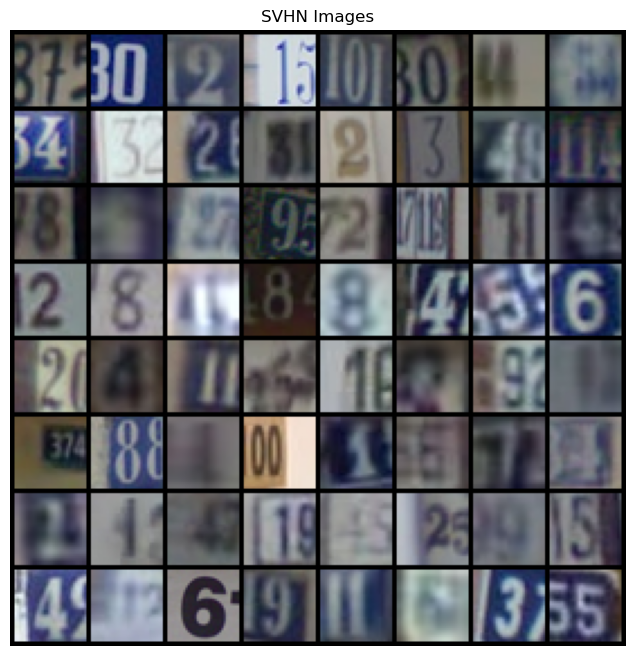

In [92]:
import matplotlib.pyplot as plt

# Get a batch of images
data_iter = iter(dataloader)
images, labels = next(data_iter)

# Create a grid
grid_img = vutils.make_grid(images[:64], nrow=8, padding=2, normalize=True)

# Display
plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("SVHN Images")
plt.imshow(grid_img.permute(1, 2, 0))  # Convert from CHW to HWC
plt.show()

## 3. Generator Architecture
The Generator transforms a latent vector (random noise) into a synthetic 32x32 RGB image using transposed convolutions, batch normalization, and ReLU activations. The final output uses `Tanh()` to match the input image range.

In [93]:
# Define Generator
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf, nc, 3, 1, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)


## 4. Discriminator Architecture
The Discriminator evaluates whether an input image is real or generated. It uses convolutional layers and LeakyReLU activations to output a single scalar per image.

In [94]:
# Define Discriminator
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x).view(-1, 1).squeeze(1)


## 5. Standard GAN Training Setup
We initialize the models and define loss using Binary Cross Entropy (BCE). Optimizers use Adam with betas tuned for GAN training. Generator and Discriminator are updated at configurable frequencies.

In [95]:
# Initialize models and optimizers
netG = Generator().to(device)
netD = Discriminator().to(device)
# Training Loop with steps_G and steps_D
num_epochs = 20
steps_G = 1  # Number of generator updates per batch
steps_D = 1  # Number of discriminator updates per batch
fixed_noise = torch.randn(64, nz, 1, 1, device=device)

G_losses = []
D_losses = []

criterion = nn.BCELoss()

optimizerD = optim.Adam(netD.parameters(), lr=0.002, betas=(0.5, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=0.002, betas=(0.5, 0.999))

for epoch in range(num_epochs):
    for i, (real_images, _) in enumerate(dataloader):
        b_size = real_images.size(0)
        real_images = real_images.to(device)
        real_labels = torch.full((b_size,), 1., device=device)
        fake_labels = torch.full((b_size,), 0., device=device)

        # Train Discriminator steps_D times
        for _ in range(steps_D):
            netD.zero_grad()
            output = netD(real_images)
            lossD_real = criterion(output, real_labels)
            lossD_real.backward()

            noise = torch.randn(b_size, nz, 1, 1, device=device)
            fake_images = netG(noise)
            output = netD(fake_images.detach())
            lossD_fake = criterion(output, fake_labels)
            lossD_fake.backward()
            optimizerD.step()

        # Train Generator steps_G times
        for _ in range(steps_G):
            netG.zero_grad()
            noise = torch.randn(b_size, nz, 1, 1, device=device)
            fake_images = netG(noise)
            output = netD(fake_images)
            lossG = criterion(output, real_labels)
            lossG.backward()
            optimizerG.step()

        # Save losses to lists (last computed in this batch)
        D_losses.append((lossD_real + lossD_fake).item())
        G_losses.append(lossG.item())

        if i % 100 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}] Batch {i}/{len(dataloader)} "
                  f"Loss D: {(lossD_real + lossD_fake).item():.4f}, Loss G: {lossG.item():.4f}")

    # Save generated images
    with torch.no_grad():
        fake = netG(fixed_noise).detach().cpu()
        vutils.save_image(fake, f"svhn_gan_output/fake_samples_epoch_{epoch+1}.png", normalize=True)





Epoch [1/20] Batch 0/573 Loss D: 1.5444, Loss G: 7.9747
Epoch [1/20] Batch 100/573 Loss D: 1.0039, Loss G: 1.7927
Epoch [1/20] Batch 200/573 Loss D: 0.6263, Loss G: 2.9160
Epoch [1/20] Batch 300/573 Loss D: 0.4632, Loss G: 1.7802
Epoch [1/20] Batch 400/573 Loss D: 0.6966, Loss G: 4.2688
Epoch [1/20] Batch 500/573 Loss D: 0.8704, Loss G: 2.4955
Epoch [2/20] Batch 0/573 Loss D: 1.1296, Loss G: 2.4985
Epoch [2/20] Batch 100/573 Loss D: 1.2217, Loss G: 2.5873
Epoch [2/20] Batch 200/573 Loss D: 1.3149, Loss G: 1.8777
Epoch [2/20] Batch 300/573 Loss D: 1.4283, Loss G: 1.8891
Epoch [2/20] Batch 400/573 Loss D: 0.8851, Loss G: 1.7430
Epoch [2/20] Batch 500/573 Loss D: 2.2342, Loss G: 1.5956
Epoch [3/20] Batch 0/573 Loss D: 1.1921, Loss G: 2.3104
Epoch [3/20] Batch 100/573 Loss D: 1.3030, Loss G: 1.2851
Epoch [3/20] Batch 200/573 Loss D: 1.3467, Loss G: 0.9956
Epoch [3/20] Batch 300/573 Loss D: 1.1447, Loss G: 1.3161
Epoch [3/20] Batch 400/573 Loss D: 1.0932, Loss G: 1.1896
Epoch [3/20] Batch 5

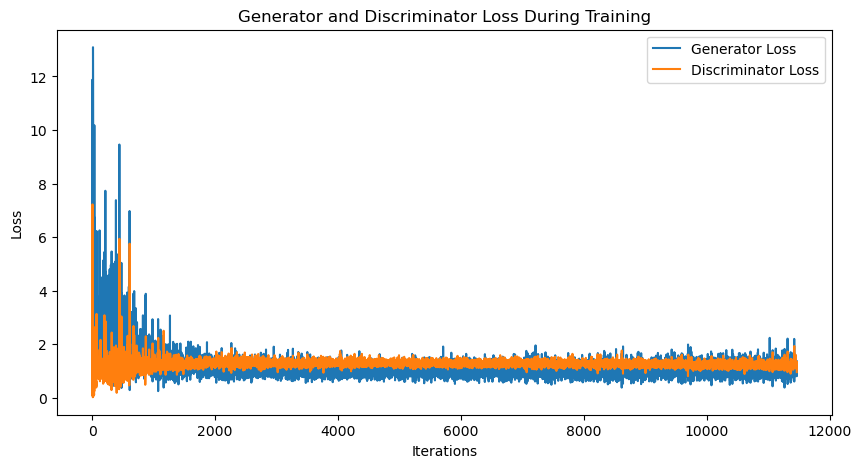

In [96]:
# Plot the losses
plt.figure(figsize=(10,5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses, label="Generator Loss")
plt.plot(D_losses, label="Discriminator Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

# 7. Sampling images

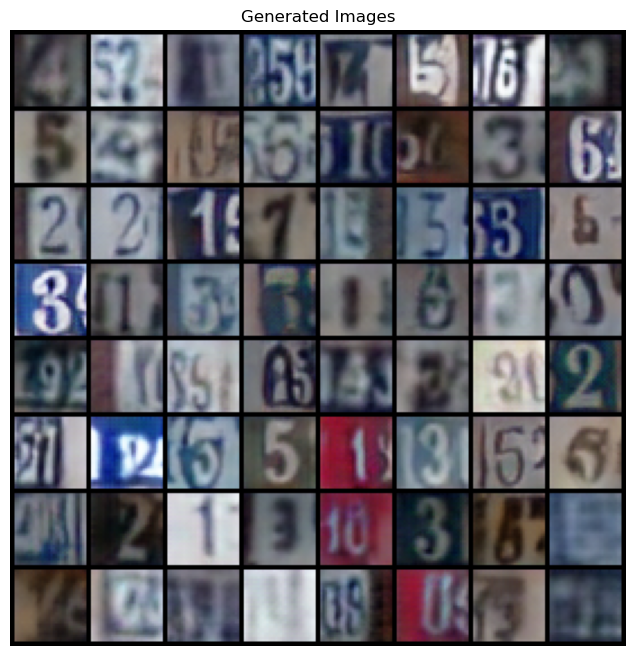

In [97]:

# Generate images using the trained generator
netG.eval()
with torch.no_grad():
    sample_noise = torch.randn(64, nz, 1, 1, device=device)
    fake_images = netG(sample_noise).detach().cpu()

# Create a grid of generated images
grid = vutils.make_grid(fake_images, nrow=8, padding=2, normalize=True)

# Display the grid
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Generated Images")
plt.imshow(grid.permute(1, 2, 0))  # Convert from CHW to HWC
plt.show()

Now we sample some images with high confidence ...

Found 2 fake images with D(x) ≥ 0.9


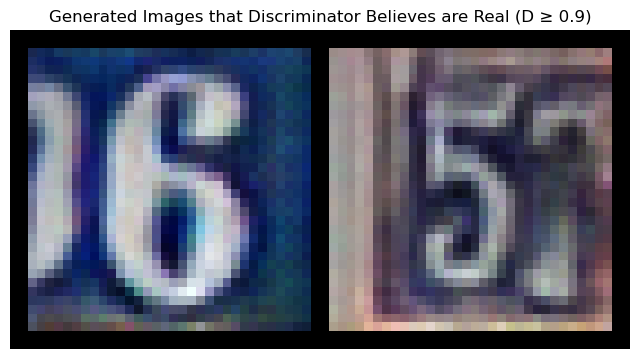

In [98]:

netG.eval()
netD.eval()


# Generate many fake images
noise = torch.randn(1000, 100, 1, 1, device=device)
with torch.no_grad():
    fake_images = netG(noise)

    # Discriminator outputs
    probs = netD(fake_images)

# Filter images with D(x) ≥ threshold
threshold = 0.9
confident_mask = probs >= threshold
confident_images = fake_images[confident_mask]

print(f"Found {confident_images.size(0)} fake images with D(x) ≥ {threshold}")

# Show up to 64 in a grid
images_to_show = confident_images[:64].cpu()
grid = vutils.make_grid(images_to_show, nrow=8, normalize=True, padding=2)

# Plot
plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title(f"Generated Images that Discriminator Believes are Real (D ≥ {threshold})")
plt.imshow(grid.permute(1, 2, 0))
plt.show()


# 8. Assesing Mode Dropping

We train a classifier to predict the proportion of each label in generated images.

In [99]:


# SVHN Classifier
class SVHNClassifier(nn.Module):
    def __init__(self):
        super(SVHNClassifier, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(3, 32, 3, 1, 1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, 1, 1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),
            nn.Linear(256, 10)  # 10 digit classes
        )

    def forward(self, x):
        return self.model(x)

# Load SVHN training data
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize(32),
    transforms.Normalize((0.5,), (0.5,))
])


# Train classifier
classifier = SVHNClassifier().to("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(classifier.parameters(), lr=0.001)

device = next(classifier.parameters()).device
for epoch in range(10):  # Enough for basic labeler
    classifier.train()
    total_loss = 0
    for imgs, labels in dataloader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        output = classifier(imgs)
        loss = criterion(output, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {total_loss:.2f}")


Epoch 1, Loss: 496.26
Epoch 2, Loss: 248.52
Epoch 3, Loss: 196.35
Epoch 4, Loss: 163.14
Epoch 5, Loss: 135.87
Epoch 6, Loss: 114.56
Epoch 7, Loss: 93.83
Epoch 8, Loss: 77.09
Epoch 9, Loss: 62.02
Epoch 10, Loss: 48.69


In [100]:
import torch.nn.functional as F

classifier.eval()
netG.eval()

# Generate fake images
noise = torch.randn(1000, 100, 1, 1, device=device)  # 1000 fake samples
with torch.no_grad():
    fake_images = netG(noise).to(device)
    outputs = classifier(fake_images)
    preds = torch.argmax(F.softmax(outputs, dim=1), dim=1)

# Count classes
unique, counts = torch.unique(preds, return_counts=True)
mode_counts = dict(zip(unique.cpu().numpy(), counts.cpu().numpy()))

print("Mode Coverage (Label Distribution of Fake Images):")
for digit in range(10):
    count = mode_counts.get(digit, 0)
    print(f"Digit {digit}: {count}")


Mode Coverage (Label Distribution of Fake Images):
Digit 0: 67
Digit 1: 204
Digit 2: 141
Digit 3: 106
Digit 4: 110
Digit 5: 98
Digit 6: 76
Digit 7: 72
Digit 8: 53
Digit 9: 73


Now we compare between the original distribution of labels and the generated one ...

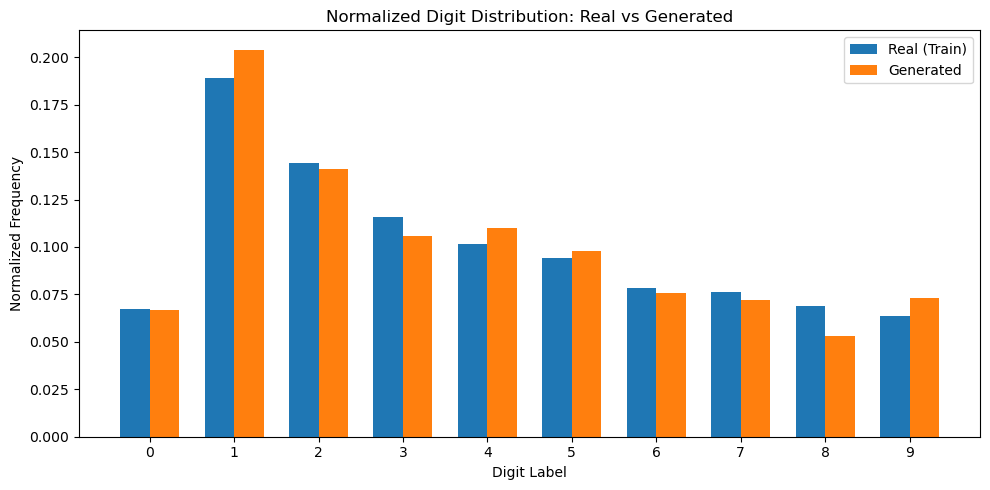

In [101]:
from collections import Counter

dataloader.labels = svhn_dataset.labels  # Ensure labels are accessible

# Count label distribution in training data
label_counts = Counter(dataloader.labels.tolist())
total_train = sum(label_counts.values())
total_fake = sum(mode_counts.values())

# Normalize both
labels = list(range(10))
real_dist = [label_counts.get(d, 0) / total_train for d in labels]
fake_dist = [mode_counts.get(d, 0) / total_fake for d in labels]

labels = list(range(10))
values = [mode_counts.get(d, 0) for d in labels]

# Plot
x = torch.arange(len(labels))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, real_dist, width, label='Real (Train)')
plt.bar(x + width/2, fake_dist, width, label='Generated')
plt.xticks(x, labels)
plt.xlabel("Digit Label")
plt.ylabel("Normalized Frequency")
plt.title("Normalized Digit Distribution: Real vs Generated")
plt.legend()
plt.tight_layout()
plt.show()

# 9. WGAN

We replace the discriminator by a critic, elimating the last sigmoidal activation ...

In [102]:
# WGAN critical discriminator
class critic(nn.Module):
    def __init__(self):
        super(critic, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=False),
        )

    def forward(self, x):
        return self.net(x).view(-1, 1).squeeze(1)

We now perform a similar training ...

In [ ]:
# Initialize Wasserstein models
netGW = Generator().to(device)
netDW = critic().to(device)


# Initialize WGAN optimizers

# Training settings
num_epochs = 20
steps_G = 1
steps_D = 1
clip_value = 0.01  # for weight clipping
fixed_noise = torch.randn(64, nz, 1, 1, device=device)

G_losses = []
D_losses = []
lr = 0.0002  # Learning rate for WGAN

# Use RMSprop for WGAN (as described in WGAN paper)
optimizerDW = optim.RMSprop(netDW.parameters(), lr=lr)
optimizerGW = optim.RMSprop(netGW.parameters(), lr=lr)

In [104]:

for epoch in range(num_epochs):
    for i, (real_images, _) in enumerate(dataloader):
        b_size = real_images.size(0)
        real_images = real_images.to(device)

        # Train Discriminator steps_D times
        for _ in range(steps_D):
            netDW.zero_grad()

            # Real
            D_real = netDW(real_images)
            lossD_real = -torch.mean(D_real)

            # Fake
            noise = torch.randn(b_size, nz, 1, 1, device=device)
            fake_images = netGW(noise).detach()
            D_fake = netDW(fake_images)
            lossD_fake = torch.mean(D_fake)

            # Total D loss
            lossD = lossD_real + lossD_fake
            lossD.backward()
            optimizerDW.step()

            # Weight clipping for WGAN
            for p in netDW.parameters():
                p.data.clamp_(-clip_value, clip_value)

        # Train Generator steps_G times
        for _ in range(steps_G):
            netGW.zero_grad()
            noise = torch.randn(b_size, nz, 1, 1, device=device)
            fake_images = netGW(noise)
            output = netDW(fake_images)
            lossG = -torch.mean(output)
            lossG.backward()
            optimizerGW.step()

        # Logging
        D_losses.append(lossD.item())
        G_losses.append(lossG.item())

        if i % 100 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}] Batch {i}/{len(dataloader)} "
                  f"Loss DW: {lossD.item():.4f}, Loss GW: {lossG.item():.4f}")

    # Save images at end of each epoch
    with torch.no_grad():
        fake = netGW(fixed_noise).detach().cpu()
        vutils.save_image(fake, f"svhn_gan_output/WGAN_fake_samples_epoch_{epoch+1}.png", normalize=True)


Epoch [1/20] Batch 0/573 Loss DW: 0.1322, Loss GW: 0.0203
Epoch [1/20] Batch 100/573 Loss DW: -0.0321, Loss GW: -0.0071
Epoch [1/20] Batch 200/573 Loss DW: -0.0377, Loss GW: -0.0376
Epoch [1/20] Batch 300/573 Loss DW: -0.0681, Loss GW: 0.0289
Epoch [1/20] Batch 400/573 Loss DW: -0.1374, Loss GW: 0.1206
Epoch [1/20] Batch 500/573 Loss DW: -0.1024, Loss GW: 0.0624
Epoch [2/20] Batch 0/573 Loss DW: -0.0941, Loss GW: 0.1638
Epoch [2/20] Batch 100/573 Loss DW: -0.0630, Loss GW: 0.0167
Epoch [2/20] Batch 200/573 Loss DW: -0.1133, Loss GW: 0.0166
Epoch [2/20] Batch 300/573 Loss DW: -0.1576, Loss GW: 0.1879
Epoch [2/20] Batch 400/573 Loss DW: -0.0863, Loss GW: 0.0907
Epoch [2/20] Batch 500/573 Loss DW: -0.0178, Loss GW: -0.0027
Epoch [3/20] Batch 0/573 Loss DW: -0.0307, Loss GW: 0.0366
Epoch [3/20] Batch 100/573 Loss DW: -0.0828, Loss GW: 0.0009
Epoch [3/20] Batch 200/573 Loss DW: -0.0282, Loss GW: 0.0415
Epoch [3/20] Batch 300/573 Loss DW: -0.0126, Loss GW: 0.0062
Epoch [3/20] Batch 400/573 L

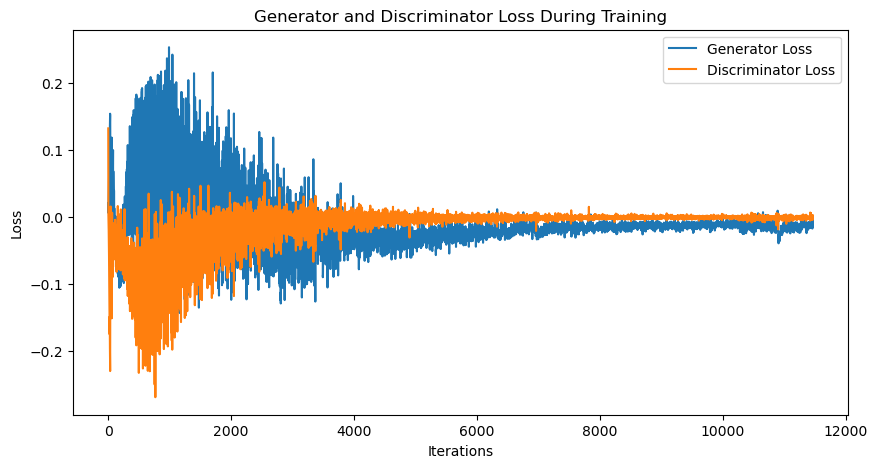

In [105]:
# Plot the losses
plt.figure(figsize=(10,5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses, label="Generator Loss")
plt.plot(D_losses, label="Discriminator Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Generate samples ...

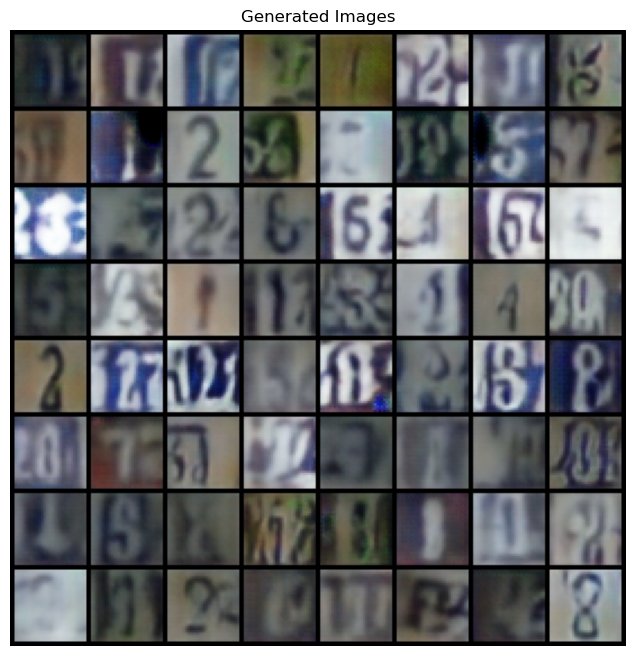

In [106]:
# Generate images using the trained generator
netGW.eval()
with torch.no_grad():
    sample_noise = torch.randn(64, nz, 1, 1, device=device)
    fake_images = netGW(sample_noise).detach().cpu()

# Create a grid of generated images
grid = vutils.make_grid(fake_images, nrow=8, padding=2, normalize=True)

# Display the grid
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Generated Images")
plt.imshow(grid.permute(1, 2, 0))  # Convert from CHW to HWC
plt.show()

Now we study the mode coverage ...

In [107]:

classifier.eval()
netGW.eval()

# Generate fake images
noise = torch.randn(1000, 100, 1, 1, device=device)  # 1000 fake samples
with torch.no_grad():
    fake_images = netG(noise).to(device)
    outputs = classifier(fake_images)
    preds = torch.argmax(F.softmax(outputs, dim=1), dim=1)

# Count classes
unique, counts = torch.unique(preds, return_counts=True)
mode_counts = dict(zip(unique.cpu().numpy(), counts.cpu().numpy()))

print("Mode Coverage (Label Distribution of Fake Images):")
for digit in range(10):
    count = mode_counts.get(digit, 0)
    print(f"Digit {digit}: {count}")


Mode Coverage (Label Distribution of Fake Images):
Digit 0: 80
Digit 1: 192
Digit 2: 147
Digit 3: 98
Digit 4: 113
Digit 5: 85
Digit 6: 82
Digit 7: 91
Digit 8: 54
Digit 9: 58


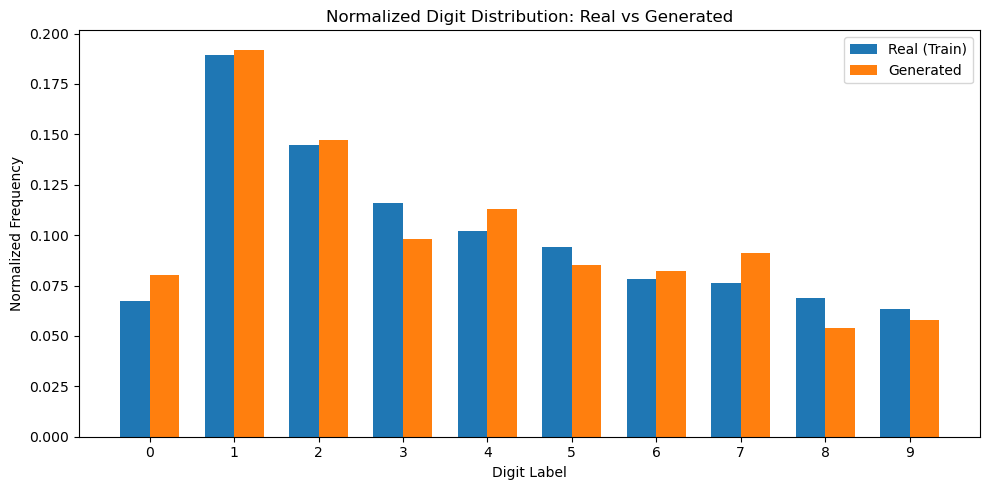

In [108]:

labels = list(range(10))
real_dist = [label_counts.get(d, 0) / total_train for d in labels]
fake_dist = [mode_counts.get(d, 0) / total_fake for d in labels]

labels = list(range(10))
values = [mode_counts.get(d, 0) for d in labels]

# Plot
x = torch.arange(len(labels))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, real_dist, width, label='Real (Train)')
plt.bar(x + width/2, fake_dist, width, label='Generated')
plt.xticks(x, labels)
plt.xlabel("Digit Label")
plt.ylabel("Normalized Frequency")
plt.title("Normalized Digit Distribution: Real vs Generated")
plt.legend()
plt.tight_layout()
plt.show()